import lib's

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid") #To set the default appearance or style of Seaborn charts.
pd.set_option("display.max_columns", None)  #To display all columns of a Pandas DataFrame when printing or displaying it.

In [2]:
df = pd.read_csv("/content/retail_orders_raw.csv")
df

,order_id,order_date,product,category,region,sales_channel,payment_method,quantity,unit_price,discount_pct,customer_rating,order_status,sales_amount
0,ORD10001,2024-04-12,Kurta,Clothing,Central,Mobile App,UPI,2,1680.42,0.25,4.0,Delivered,2520.63
1,ORD10002,2025-03-11,Smart Watch,Electronics,West,Store,Card,1,4167.93,0.15,3.6,Delivered,3542.74
2,ORD10003,2024-09-27,Cookware Set,Home & Kitchen,Central,Mobile App,Cash on Delivery,1,3464.30,0.20,3.7,Delivered,2771.44
3,ORD10004,2024-04-16,Desk Lamp,Home & Kitchen,Central,Website,Card,3,3662.57,0.10,3.3,Delivered,9888.94
4,ORD10005,2024-03-12,Keyboard,Electronics,West,Marketplace,Cash on Delivery,3,13483.35,0.05,4.7,Cancelled,38427.55
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2202,ORD11816,2024-10-31,Sunscreen,Beauty,East,Mobile App,Card,2,1695.31,0.05,4.2,Delivered,3221.09
2203,ORD11772,2024-11-15,Shampoo,Beauty,West,Store,Cash on Delivery,1,596.34,0.15,3.8,Delivered,506.89
2204,ORD10989,2025-11-20,Bluetooth Speaker,Electronics,Central,Website,UPI,3,707.22,0.10,3.2,Delivered,1909.49
2205,ORD10318,2025-04-14,Yoga Mat,Sports,South,Marketplace,Card,4,1818.82,0.10,3.8,Returned,6547.75


understand the data (data exploration)

In [3]:
print( df.shape)
print(df.columns.tolist())
df.info()

(2207, 13)
['order_id', 'order_date', 'product', 'category', 'region', 'sales_channel', 'payment_method', 'quantity', 'unit_price', 'discount_pct', 'customer_rating', 'order_status', 'sales_amount']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2207 entries, 0 to 2206
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_id         2207 non-null   object 
 1   order_date       2207 non-null   object 
 2   product          2197 non-null   object 
 3   category         2207 non-null   object 
 4   region           2195 non-null   object 
 5   sales_channel    2207 non-null   object 
 6   payment_method   2207 non-null   object 
 7   quantity         2207 non-null   int64  
 8   unit_price       2207 non-null   float64
 9   discount_pct     2199 non-null   float64
 10  customer_rating  2189 non-null   float64
 11  order_status     2207 non-null   object 
 12  sales_amount     2207 non-null   float64
dtyp

In [4]:
df.describe(include="all").T
#T -> transpose (rows become clmns, vice-versa)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,2207,2200,ORD10978,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,2207,682,2024-02-08,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product,2197,25,Jeans,129,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,2207,14,Clothing,541,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,2195,5,South,481,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sales_channel,2207,4,Mobile App,689,NaN,NaN,NaN,NaN,NaN,NaN,NaN
payment_method,2207,4,UPI,866,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quantity,2207.0,NaN,NaN,NaN,1.913457,1.112541,-2.0,1.0,2.0,3.0,5.0
unit_price,2207.0,NaN,NaN,NaN,3240.835016,3215.543699,-100.0,1120.96,2213.53,4019.16,14940.03
discount_pct,2199.0,NaN,NaN,NaN,0.100387,0.073602,0.0,0.05,0.1,0.15,0.25


data cleaning

terminating exact duplicate rows & standardize the text values

In [5]:
print("Rows before removing duplicates:", len(df))

df = df.drop_duplicates().copy() #Remove duplicate rows and create an independent copy of the cleaned DataFrame

print("Rows after removing duplicates:", len(df))

text_columns = ["product", "category", "region", "sales_channel",
    "payment_method", "order_status"]

for col in text_columns:
    df.loc[:, col] = df[col].astype("string").str.strip()

df["category"] = df["category"].str.title()
df["region"] = df["region"].str.title()
df["sales_channel"] = df["sales_channel"].str.title()
df["payment_method"] = df["payment_method"].str.title()
df["order_status"] = df["order_status"].str.title()

df["category"].value_counts()

Rows before removing duplicates: 2207
Rows after removing duplicates: 2200


,count
category,
Clothing,540
Electronics,471
Home & Kitchen,429
Beauty,418
Sports,342


convert the order date to datetime type

Date columns should be real datetime values to support monthly and yearly analysis. errors="coerce" turns unparseable dates into missing values rather than stopping the code.

In [6]:
df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")
print("Invalid/missing order dates:", df["order_date"].isna().sum())

Invalid/missing order dates: 0


checking missing values to handle them, if no missing values are there then no need to handle

In [7]:
print(df.isna().sum())

order_id            0
order_date          0
product            10
category            0
region             12
sales_channel       0
payment_method      0
quantity            0
unit_price          0
discount_pct        8
customer_rating    18
order_status        0
sales_amount        0
dtype: int64


since, missing values are existing, will handle them later.

validate numeric values

Quantity and unit price must be positive. We will flag(identify) invalid records, inspect them, and remove them from this sales analysis rather than pretending they are valid sales.

In [8]:
invalid_mask = (df["quantity"] <= 0) | (df["unit_price"] <= 0)
print("Invalid quantity/price rows:", invalid_mask.sum())
df.loc[invalid_mask, ["order_id", "quantity", "unit_price", "sales_amount"]].head(10)

Invalid quantity/price rows: 14


,order_id,quantity,unit_price,sales_amount
159,ORD10160,4,0.00,4723.74
223,ORD10224,3,-100.00,798.71
342,ORD10343,0,9114.97,7291.98
361,ORD10362,2,0.00,5659.72
396,ORD10397,-2,1998.15,1698.43
643,ORD10644,1,0.00,2215.48
901,ORD10902,-2,7090.36,11344.58
1022,ORD11023,0,1560.90,2809.62
1171,ORD11172,0,683.40,2186.88
1459,ORD11460,2,-100.00,7374.01


In [9]:
print("Shape before removing invalid quantity/price rows:", df.shape)

df = df.loc[~invalid_mask].copy()

print("Shape after removing invalid quantity/price rows:", df.shape)

Shape before removing invalid quantity/price rows: (2200, 13)
Shape after removing invalid quantity/price rows: (2186, 13)


invalid_mask = (df["quantity"] <= 0) | (df["unit_price"] <= 0)

If the quantity or unit price is zero or negative, the condition returns True, meaning that the row is invalid.

~invalid_mask : The ~ symbol reverses the Boolean values.

df.loc[~invalid_mask]: df.loc[...] selects rows based on a condition.

~invalid_mask selects only the rows where the original invalid condition was False.

recalculate sales amount

The original sales amount may no longer be correct after missing discounts are filled or records are cleaned.

Recalculate it using:

Sales Amount = Quantity × Unit Price × (1 − Discount Percentage)

The discount is stored as a decimal fraction, so 0.10 means 10%.

In [10]:
df["sales_amount"] = (df["quantity"] * df["unit_price"] * (1 - df["discount_pct"])).round(2)

df[["quantity", "unit_price", "discount_pct", "sales_amount"]].head()

,quantity,unit_price,discount_pct,sales_amount
0,2,1680.42,0.25,2520.63
1,1,4167.93,0.15,3542.74
2,1,3464.30,0.20,2771.44
3,3,3662.57,0.10,9888.94
4,3,13483.35,0.05,38427.55


final quality check

Check duplicates, missing values, data types, and whether invalid values remain. A clean dataset does not necessarily mean every field is perfect. it means the choices and remaining limitations are understood.

In [11]:
print("Final shape:", df.shape)
print("\nMissing values:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nInvalid quantities:", (df["quantity"] <= 0).sum())
print("Invalid prices:", (df["unit_price"] <= 0).sum())
df.info()

Final shape: (2186, 13)

Missing values:
order_id            0
order_date          0
product            10
category            0
region             12
sales_channel       0
payment_method      0
quantity            0
unit_price          0
discount_pct        8
customer_rating    18
order_status        0
sales_amount        8
dtype: int64

Duplicate rows: 0

Invalid quantities: 0
Invalid prices: 0
<class 'pandas.core.frame.DataFrame'>
Index: 2186 entries, 0 to 2199
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   order_id         2186 non-null   object        
 1   order_date       2186 non-null   datetime64[ns]
 2   product          2176 non-null   object        
 3   category         2186 non-null   object        
 4   region           2174 non-null   object        
 5   sales_channel    2186 non-null   object        
 6   payment_method   2186 non-null   object        
 7   quantity        

missing values are existing , need to handle them.

In [12]:
df[df["product"].isna()].head(10)

,order_id,order_date,product,category,region,sales_channel,payment_method,quantity,unit_price,discount_pct,customer_rating,order_status,sales_amount
217,ORD10218,2025-01-19,<NA>,Sports,West,Website,Net Banking,2,1949.47,0.00,4.2,Delivered,3898.94
382,ORD10383,2025-04-21,<NA>,Electronics,West,Mobile App,Cash On Delivery,1,11671.35,0.00,3.9,Delivered,11671.35
505,ORD10506,2025-07-30,<NA>,Clothing,West,Website,Cash On Delivery,3,596.44,0.10,3.4,Delivered,1610.39
715,ORD10716,2024-09-12,<NA>,Clothing,West,Mobile App,Net Banking,1,1628.17,0.10,4.7,Delivered,1465.35
824,ORD10825,2024-07-13,<NA>,Home & Kitchen,Central,Mobile App,Upi,1,3180.39,0.10,3.4,Delivered,2862.35
863,ORD10864,2025-09-16,<NA>,Beauty,East,Store,Cash On Delivery,1,1583.44,0.15,4.1,Delivered,1345.92
1023,ORD11024,2024-06-13,<NA>,Electronics,East,Store,Cash On Delivery,1,13883.51,0.10,2.9,Cancelled,12495.16
1755,ORD11756,2024-09-29,<NA>,Electronics,North,Marketplace,Card,3,8338.94,0.00,4.2,Delivered,25016.82
2000,ORD12001,2025-05-09,<NA>,Sports,South,Marketplace,Cash On Delivery,3,2254.70,0.15,4.3,Delivered,5749.48
2044,ORD12045,2025-12-04,<NA>,Home & Kitchen,Central,Website,Upi,1,804.00,0.10,4.6,Cancelled,723.60


handling product clmn na values

In [13]:
df["product"] = df["product"].fillna("Unknown Product")

In [14]:
print("Missing product values:", df["product"].isna().sum())

Missing product values: 0


handling region clmn na vals

In [15]:
df[df["region"].isna()].head()

,order_id,order_date,product,category,region,sales_channel,payment_method,quantity,unit_price,discount_pct,customer_rating,order_status,sales_amount
65,ORD10066,2024-03-21,Lip Balm,Beauty,<NA>,Website,Card,4,227.13,0.00,4.1,Delivered,908.52
161,ORD10162,2025-07-27,Mixer Grinder,Home & Kitchen,<NA>,Store,Upi,1,1436.95,0.10,4.2,Cancelled,1293.26
478,ORD10479,2024-09-10,Power Bank,Electronics,<NA>,Marketplace,Card,1,11740.91,0.00,4.4,Cancelled,11740.91
538,ORD10539,2024-07-10,Storage Box,Home & Kitchen,<NA>,Mobile App,Upi,1,2491.93,0.20,3.8,Delivered,1993.54
791,ORD10792,2025-03-10,Yoga Mat,Sports,<NA>,Mobile App,Net Banking,1,539.12,0.25,5.0,Delivered,404.34


In [16]:
df["region"] = df["region"].fillna("Unknown")

In [17]:
print("Missing regions:", df["region"].isna().sum())

Missing regions: 0


handling discount_pct clmn na values

In [18]:
df[df["discount_pct"].isna()].head()

,order_id,order_date,product,category,region,sales_channel,payment_method,quantity,unit_price,discount_pct,customer_rating,order_status,sales_amount
41,ORD10042,2025-07-20,Bluetooth Speaker,Electronics,East,Mobile App,Net Banking,2,9929.69,NaN,4.2,Delivered,NaN
453,ORD10454,2024-07-07,Running Shoes,Sports,South,Marketplace,Cash On Delivery,3,4903.84,NaN,5.0,Delivered,NaN
548,ORD10549,2025-11-25,Dumbbells,Sports,West,Marketplace,Cash On Delivery,2,2330.89,NaN,4.8,Delivered,NaN
851,ORD10852,2024-04-30,Shampoo,Beauty,West,Mobile App,Cash On Delivery,2,673.61,NaN,4.9,Cancelled,NaN
1021,ORD11022,2024-10-17,Sunscreen,Beauty,West,Store,Cash On Delivery,1,1702.77,NaN,3.5,Delivered,NaN


In [19]:
df["discount_pct"] = df["discount_pct"].fillna(0)

In [20]:
print("Missing discounts:", df["discount_pct"].isna().sum())

Missing discounts: 0


handling customer_rating na vals

In [21]:
df[df["customer_rating"].isna()].head()

,order_id,order_date,product,category,region,sales_channel,payment_method,quantity,unit_price,discount_pct,customer_rating,order_status,sales_amount
137,ORD10138,2024-07-25,Sneakers,Clothing,East,Marketplace,Upi,1,782.96,0.05,NaN,Delivered,743.81
290,ORD10291,2025-02-25,Mixer Grinder,Home & Kitchen,North,Marketplace,Card,2,4978.49,0.10,NaN,Delivered,8961.28
470,ORD10471,2024-07-22,Mixer Grinder,Home & Kitchen,North,Website,Net Banking,2,345.36,0.00,NaN,Returned,690.72
560,ORD10561,2024-06-25,Shampoo,Beauty,Central,Website,Net Banking,3,344.53,0.20,NaN,Returned,826.87
886,ORD10887,2025-05-22,Lip Balm,Beauty,South,Store,Upi,1,1510.87,0.20,NaN,Delivered,1208.70


In [22]:
df["customer_rating"] = df["customer_rating"].fillna(df["customer_rating"].median())

In [23]:
print("Missing ratings:", df["customer_rating"].isna().sum())

Missing ratings: 0


In [24]:
df["sales_amount"] = (df["quantity"] * df["unit_price"] * (1 - df["discount_pct"])).round(2)

In [25]:
print("Missing sales amounts:", df["sales_amount"].isna().sum())

Missing sales amounts: 0


In [26]:
print(df.isna().sum())

order_id           0
order_date         0
product            0
category           0
region             0
sales_channel      0
payment_method     0
quantity           0
unit_price         0
discount_pct       0
customer_rating    0
order_status       0
sales_amount       0
dtype: int64


finallyy....hanlded all missing vals!!🥳

now, let's do feature enggg

In [27]:
df["year"] = df["order_date"].dt.year
df["month"] = df["order_date"].dt.month
df["month_name"] = df["order_date"].dt.strftime("%b")
df["year_month"] = df["order_date"].dt.to_period("M").astype(str)

df["order_value_band"] = pd.cut(
    df["sales_amount"],
    bins=[0, 1000, 5000, 10000, np.inf],
    labels=["Under ₹1,000", "₹1,000–₹5,000", "₹5,000–₹10,000", "Above ₹10,000"],
    right=False)
df[["order_date", "year", "month", "month_name", "year_month",
    "sales_amount", "order_value_band"]].head()

,order_date,year,month,month_name,year_month,sales_amount,order_value_band
0,2024-04-12,2024,4,Apr,2024-04,2520.63,"₹1,000–₹5,000"
1,2025-03-11,2025,3,Mar,2025-03,3542.74,"₹1,000–₹5,000"
2,2024-09-27,2024,9,Sep,2024-09,2771.44,"₹1,000–₹5,000"
3,2024-04-16,2024,4,Apr,2024-04,9888.94,"₹5,000–₹10,000"
4,2024-03-12,2024,3,Mar,2024-03,38427.55,"Above ₹10,000"


explanation: We are performing feature engineering. We take the existing sales_amount column and create a new column called order_value_band to categorize orders based on their sales value.

instead of seeing sales amounts like ₹500, ₹2,500 and ₹8,000, we can categorize them as low-value, medium-value and high-value orders.

df["order_value_band"] =This column will store the category assigned to each order based on its sales amount.

pd.cut() is a Pandas function used to divide numerical data into intervals, also called bins, and assign a category to each value. it helps us convert numerical values into meaningful categories.

right=False, the intervals work like this:

Sales amount Category

₹0 ≤ sales < ₹1,000 Under ₹1,000

means it'll exclude 1000 , that's it.

right=True is the default. It includes the right boundary and excludes the left boundary .

right=True → include the right boundary.

right=False → include the left boundary.

Exploratory Data Analysis (EDA) EDA is the process of exploring data using summaries and visualizations before making conclusions.

In [28]:
print("Total orders:", df["order_id"].nunique())
print("Total sales value: ₹{:,.2f}".format(df["sales_amount"].sum()))
print("Average order value: ₹{:,.2f}".format(df["sales_amount"].mean()))
print("Average customer rating:", round(df["customer_rating"].mean(), 2))
print("\nOrder status counts:")
print(df["order_status"].value_counts())

Total orders: 2186
Total sales value: ₹12,358,576.57
Average order value: ₹5,653.51
Average customer rating: 3.97

Order status counts:
order_status
Delivered    1869
Cancelled     202
Returned      115
Name: count, dtype: int64


{} Placeholder where the value will be inserted

: Starts the formatting instructions

, Adds commas to separate thousands

.2 Displays two digits after the decimal point

f Formats the value as a floating-point number &

format() is a Python method used to insert values into a string and format how those values should be displayed.

visualisation implement karo🎨

1.how do sales change over time?

2.Which regions have the highest sales?

3.Which sales channels are used most?

4.What is the distribution of order values?

5.Are ratings different across categories?

6.How are numeric variables related?

6.What is the order-status mix?

Use NumPy for a quick numerical summary. NumPy functions such as mean, median, and percentile summarize numeric arrays. Pandas also offers similar methods; this section demonstrates NumPy explicitly.

⭐ Export the cleaned dataset

Save the cleaned result to a new file so the original raw dataset remains unchanged.

In [29]:
'''
df.to_csv("retail_orders_cleaned.csv", index=False)
print("Cleaned dataset saved as retail_orders_cleaned.csv")'''

'\ndf.to_csv("retail_orders_cleaned.csv", index=False)\nprint("Cleaned dataset saved as retail_orders_cleaned.csv")'

Additional Que's

1. Which category has the highest average order value, not total sales?
2. Which payment method is used most often?
3. Compare total sales for Delivered vs Cancelled vs Returned orders. Should cancelled/returned orders be included in net revenue? Explain your assumption.
4. Create a pie chart of order status percentages.
5. Plot quantity against sales amount using a scatter plot.
6. Find the top 5 products by total sales.
7. Compare sales by category and region using a grouped bar chart or pivot table.
8. What are the limitations of this synthetic dataset?

In [30]:
df.to_csv("retail_orders_cleaned.csv", index=False)
print("Cleaned dataset saved as retail_orders_cleaned.csv")

Cleaned dataset saved as retail_orders_cleaned.csv


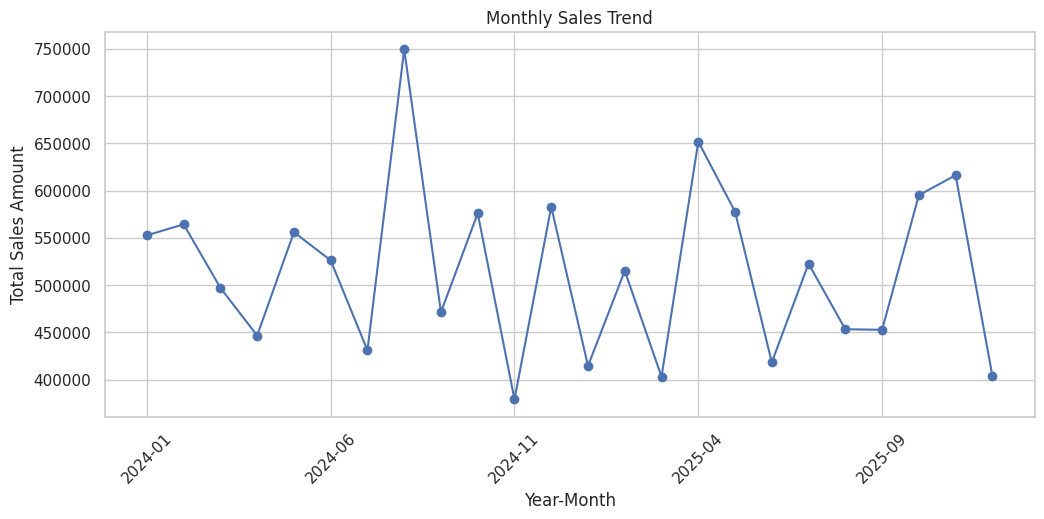

In [31]:
#1.how do sales change over time?
montly_sales=df.groupby("year_month")["sales_amount"].sum()
plt.figure(figsize=(12,5))
montly_sales.plot(x="year_month",y="sales_amount",marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Year-Month")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()


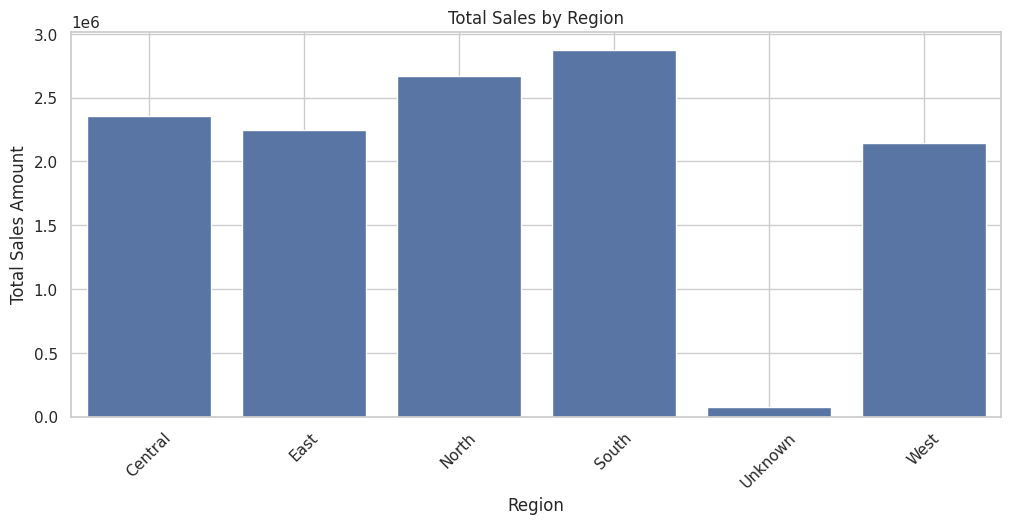

In [32]:
#2.Which regions have the highest sales?
region_sales=df.groupby("region")["sales_amount"].sum()
plt.figure(figsize=(12,5))
sns.barplot(x=region_sales.index,y=region_sales.values)
plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

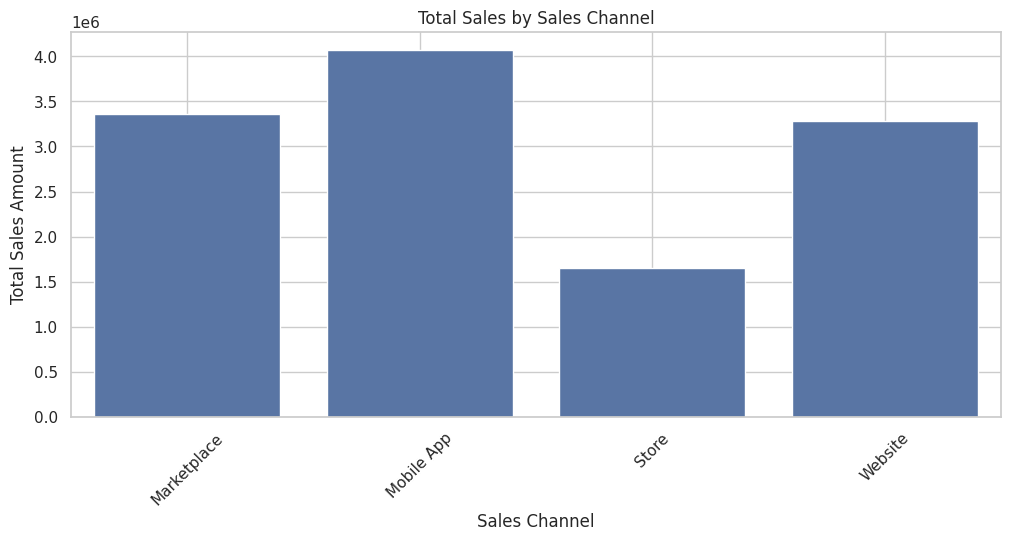

In [33]:
#3.Which sales channels are used most?
channel_sales=df.groupby("sales_channel")["sales_amount"].sum()
plt.figure(figsize=(12,5))
sns.barplot(x=channel_sales.index,y=channel_sales.values)
plt.title("Total Sales by Sales Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

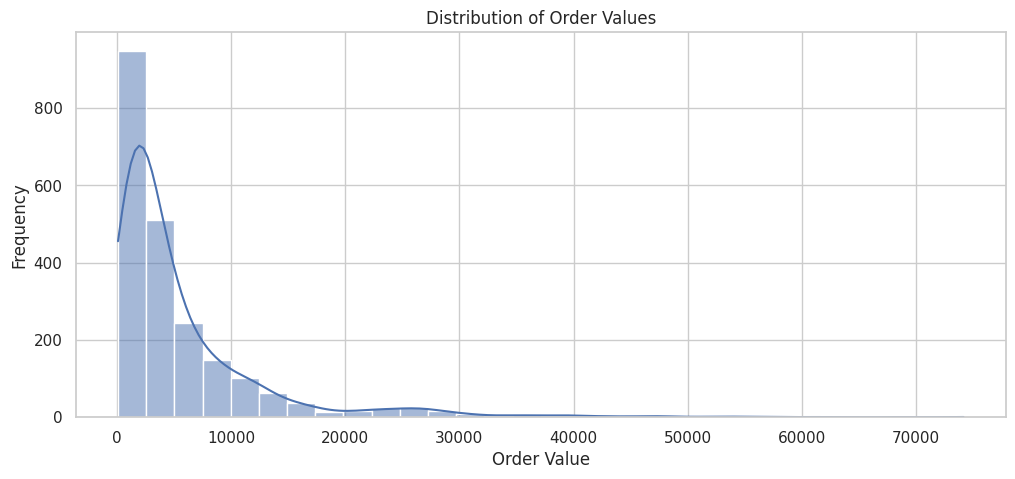

In [34]:
#4.What is the distribution of order values?
plt.figure(figsize=(12,5))
sns.histplot(data=df,x="sales_amount",bins=30,kde=True)
plt.title("Distribution of Order Values")
plt.xlabel("Order Value")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()

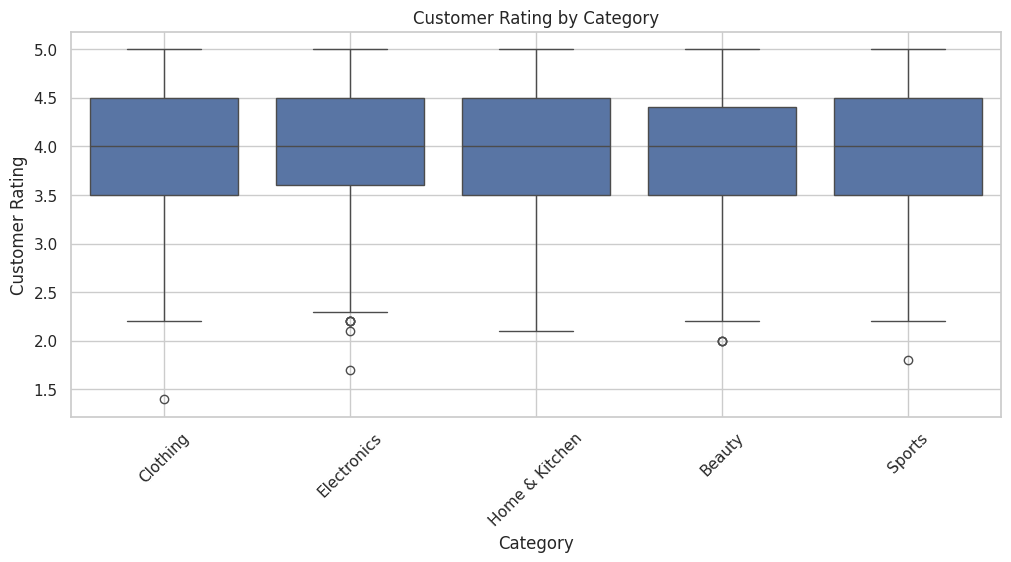

In [35]:
#5.Are ratings different across categories?
plt.figure(figsize=(12,5))
sns.boxplot(data=df,x="category",y="customer_rating")
plt.title("Customer Rating by Category")
plt.xlabel("Category")
plt.ylabel("Customer Rating")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

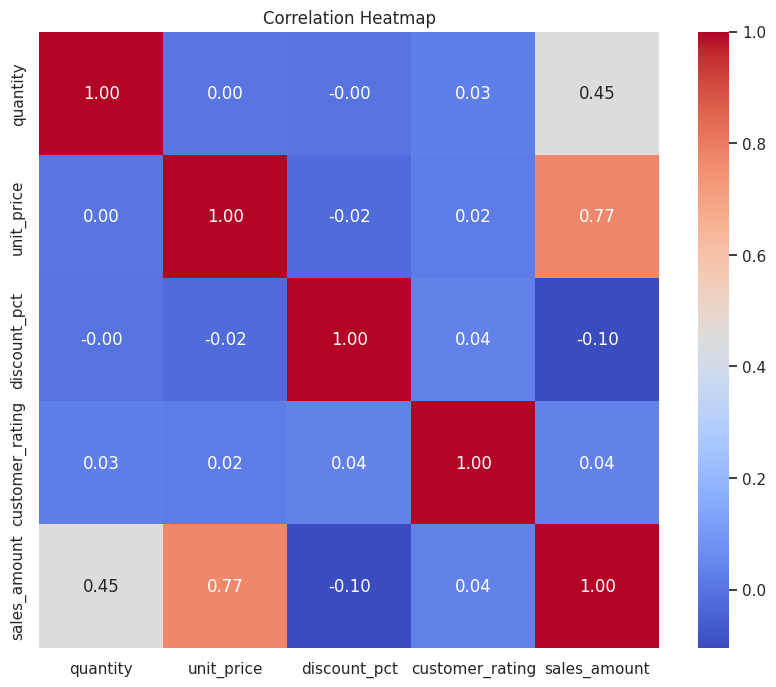

In [36]:
#6.How are numeric variables related?
numeric_df = df[["quantity", "unit_price", "discount_pct","customer_rating", "sales_amount"]]

correlation = numeric_df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()


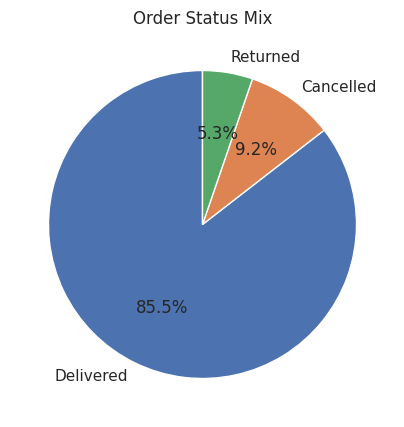

In [37]:
#7.What is the order-status mix?
status_counts=df["order_status"].value_counts()
plt.figure(figsize=(12,5))
plt.pie(status_counts.values,labels=status_counts.index,autopct="%1.1f%%",startangle=90)
plt.title("Order Status Mix")
plt.show()

Additional Questions

In [38]:
#1. Which category has the highest average order value, not total sales?
category_avg_order_value=df.groupby("category")["sales_amount"].mean().sort_values(ascending=False)
print(category_avg_order_value)
print("\nCategory with the highest average order value:")
print(category_avg_order_value.idxmax())

category
Electronics       13054.379380
Sports             5637.733794
Home & Kitchen     4370.926494
Clothing           3312.300745
Beauty             1672.952572
Name: sales_amount, dtype: float64

Category with the highest average order value:
Electronics


In [39]:
#2. Which payment method is used most often?
payment_method_counts=df["payment_method"].value_counts()
print(payment_method_counts)
print("\nPayment method used most often:")
print(payment_method_counts.idxmax())

payment_method
Upi                 855
Card                650
Cash On Delivery    420
Net Banking         261
Name: count, dtype: int64

Payment method used most often:
Upi


In [40]:
#3. Compare total sales for Delivered vs Cancelled vs Returned orders.
status_sales=df.groupby("order_status")["sales_amount"].sum()
print(status_sales)

order_status
Cancelled     1167982.77
Delivered    10565570.37
Returned       625023.43
Name: sales_amount, dtype: float64


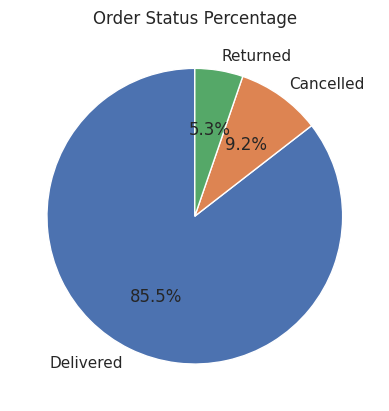

In [41]:
#4. Create a pie chart of order status percentages.
status=df["order_status"].value_counts()
plt.pie(status.values,labels=status.index,autopct="%1.1f%%",startangle=90)
plt.title("Order Status Percentage")
plt.show()

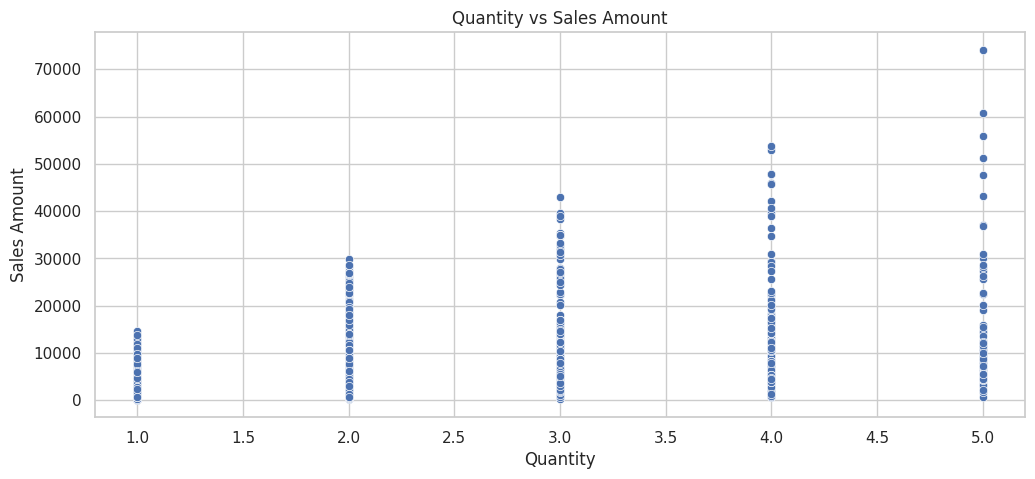

In [42]:
#5. Plot quantity against sales amount using a scatter plot.
plt.figure(figsize=(12,5))
sns.scatterplot(data=df,x="quantity",y="sales_amount")
plt.title("Quantity vs Sales Amount")
plt.xlabel("Quantity")
plt.ylabel("Sales Amount")
plt.grid(True)
plt.show()

In [43]:
#6. Find the top 5 products by total sales.
top_products=df.groupby("product")["sales_amount"].sum().sort_values(ascending=False).head(5)
print(top_products)


product
Power Bank           1566224.34
Bluetooth Speaker    1247251.98
Keyboard             1187238.14
Wireless Earbuds     1112722.32
Smart Watch           946829.44
Name: sales_amount, dtype: float64


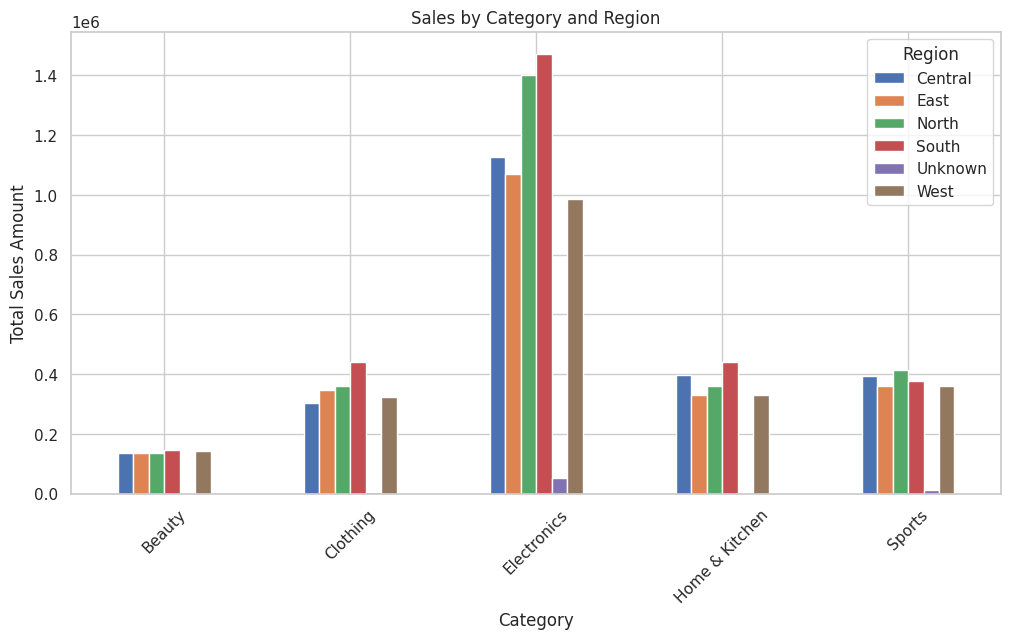

In [44]:
#7. Compare sales by category and region using a grouped bar chart or pivot table.
category_region_sales=pd.pivot_table(df,values="sales_amount",index="category",columns="region",aggfunc="sum")
category_region_sales.plot(kind="bar", figsize=(12, 6))
plt.title("Sales by Category and Region")
plt.xlabel("Category")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=45)
plt.legend(title="Region")
plt.show()

In [45]:
sales = df["sales_amount"].to_numpy()

print("Mean Sales:", np.mean(sales))
print("Median Sales:", np.median(sales))
print("25th Percentile:", np.percentile(sales, 25))
print("50th Percentile:", np.percentile(sales, 50))
print("75th Percentile:", np.percentile(sales, 75))

Mean Sales: 5653.51169716377
Median Sales: 3076.335
25th Percentile: 1510.205
50th Percentile: 3076.335
75th Percentile: 6698.51


Q8. What are the limitations of this synthetic dataset?
This is a theory question. You can write the following answer in your project documentation:
1. Synthetic data: The dataset is artificially generated and may not represent actual customer purchasing behaviour.
2. Limited records: It contains only 2,207 original rows, so the findings may not represent a large retail business.
3. Missing values: Some original records had missing product, region, discount and customer-rating values.
4. Limited customer information: The dataset does not contain detailed customer demographics or customer IDs.
5. Limited time period: The data covers a limited period, so long-term trends cannot be established.
6. Limited business information: It does not provide actual refund amounts, shipping costs, marketing expenses or inventory information.
7. Possible bias: The patterns in synthetic data may not reflect real-world business conditions.

In [47]:
print("========== FINAL PROJECT VERIFICATION ==========")

print("\n1. Dataset Shape:")
print(df.shape)

print("\n2. Total Unique Orders:")
print(df["order_id"].nunique())

print("\n3. Missing Values:")
print(df.isna().sum())

print("\n4. Total Missing Values:")
print(df.isna().sum().sum())

print("\n5. Duplicate Rows:")
print(df.duplicated().sum())

print("\n6. Invalid Quantities:")
print((df["quantity"] <= 0).sum())

print("\n7. Invalid Unit Prices:")
print((df["unit_price"] <= 0).sum())

print("\n8. Total Sales:")
print(round(df["sales_amount"].sum(), 2))

print("\n9. Average Order Value:")
print(round(df["sales_amount"].mean(), 2))

print("\n10. Order Status Counts:")
print(df["order_status"].value_counts())

print("\n11. Feature Engineering Columns:")
print(["year", "month", "month_name",
       "year_month", "order_value_band"])

print("\n========== VERIFICATION COMPLETED ==========")

========== FINAL PROJECT VERIFICATION ==========

1. Dataset Shape:
(2186, 18)

2. Total Unique Orders:
2186

3. Missing Values:
order_id            0
order_date          0
product             0
category            0
region              0
sales_channel       0
payment_method      0
quantity            0
unit_price          0
discount_pct        0
customer_rating     0
order_status        0
sales_amount        0
year                0
month               0
month_name          0
year_month          0
order_value_band    0
dtype: int64

4. Total Missing Values:
0

5. Duplicate Rows:
0

6. Invalid Quantities:
0

7. Invalid Unit Prices:
0

8. Total Sales:
12358576.57

9. Average Order Value:
5653.51

10. Order Status Counts:
order_status
Delivered    1869
Cancelled     202
Returned      115
Name: count, dtype: int64

11. Feature Engineering Columns:
['year', 'month', 'month_name', 'year_month', 'order_value_band']

========== VERIFICATION COMPLETED ==========


In [46]:
df.to_csv("retail_orders_cleaned.csv", index=False)
print("Cleaned dataset saved as retail_orders_cleaned.csv")

Cleaned dataset saved as retail_orders_cleaned.csv
